In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [ ]:
df = pd.read_csv("D")
print("Dataset loaded successfully")

Dataset loaded successfully


In [ ]:
df.shape

(8950, 18)

In [ ]:
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,Cluster
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12,3
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12,1
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12,3
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12,3
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12,3


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [ ]:
df.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


In [ ]:
df.isnull().sum()

,0
CUST_ID,0
BALANCE,0
BALANCE_FREQUENCY,0
PURCHASES,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES_FREQUENCY,0
PURCHASES_INSTALLMENTS_FREQUENCY,0


In [ ]:
# Select PURCHASES and CASH_ADVANCE as feature variables for clustering
X = df[['PURCHASES', 'CASH_ADVANCE']]
print("Features selected for clustering: PURCHASES and CASH_ADVANCE")

Features selected for clustering: PURCHASES and CASH_ADVANCE


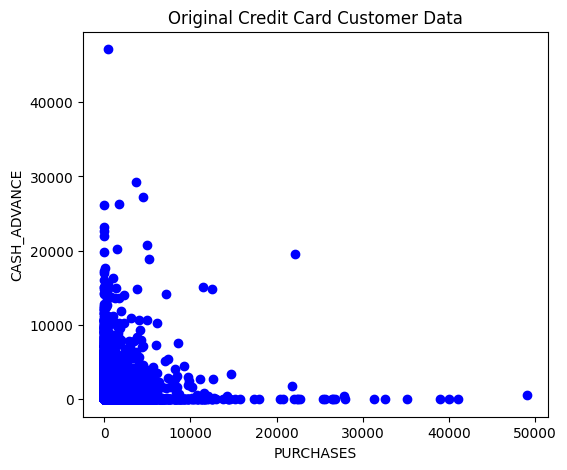

In [ ]:
# Visualize the original data points by plotting PURCHASES against CASH_ADVANCE
plt.figure(figsize=(6,5))
plt.scatter(X['PURCHASES'], X['CASH_ADVANCE'], color='blue')
plt.xlabel("PURCHASES")
plt.ylabel("CASH_ADVANCE")
plt.title("Original Credit Card Customer Data")
plt.show()

In [ ]:
# Apply StandardScaler to normalize the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature scaling complete using StandardScaler")

Feature scaling complete using StandardScaler


In [ ]:
# Initialize the K-Means algorithm with 5 clusters and train it on the scaled features
kmeans = KMeans(n_clusters=5, random_state=42)
kmeans.fit(X_scaled)
print("Model trained successfully")

Model trained successfully


In [ ]:
# Assign cluster labels to the original dataset and display the first 5 rows with clusters
labels = kmeans.labels_
df['Cluster'] = labels
df[['PURCHASES', 'CASH_ADVANCE', 'Cluster']].head()

,PURCHASES,CASH_ADVANCE,Cluster
0,95.40,0.000000,3
1,0.00,6442.945483,1
2,773.17,0.000000,3
3,1499.00,205.788017,3
4,16.00,0.000000,3


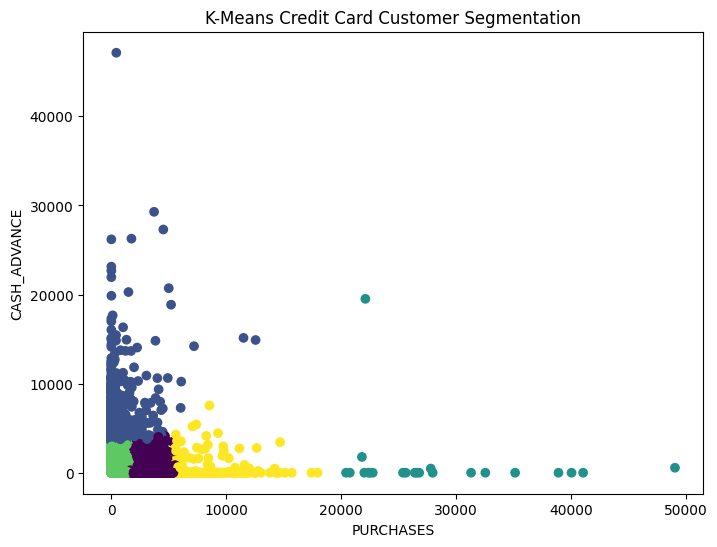

In [ ]:
# Visualize the clusters by plotting PURCHASES against CASH_ADVANCE
plt.figure(figsize=(8,6))
plt.scatter(X['PURCHASES'], X['CASH_ADVANCE'], c=labels, cmap='viridis')
plt.xlabel("PURCHASES")
plt.ylabel("CASH_ADVANCE")
plt.title("K-Means Credit Card Customer Segmentation")
plt.show()

In [ ]:
# Calculate and display model evaluation metrics: Silhouette Score, WCSS (Inertia),and Davies-Bouldin Index
score = silhouette_score(X_scaled, labels)
print("Silhouette Score:", score)
wcss = kmeans.inertia_
print(f"WCSS (Inertia): {wcss:.2f}")
db_score = davies_bouldin_score(X_scaled, labels)
print("Davies-Bouldin Index:", db_score)

Silhouette Score: 0.5413048329693434
WCSS (Inertia): 5035.75
Davies-Bouldin Index: 0.6340532748568539
